In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

In [35]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("thedevastator/hotel-bookings-analysis")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Ganesh\.cache\kagglehub\datasets\thedevastator\hotel-bookings-analysis\versions\1


In [36]:
df=pd.read_csv(f'{path}/hotel_bookings.csv')

In [37]:
df.head()

,index,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,0,Resort Hotel,0,342,2015,July,27,1,0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
1,1,Resort Hotel,0,737,2015,July,27,1,0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
2,2,Resort Hotel,0,7,2015,July,27,1,0,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
3,3,Resort Hotel,0,13,2015,July,27,1,0,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
4,4,Resort Hotel,0,14,2015,July,27,1,0,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-15


In [38]:
df.isnull().sum()

index                                  0
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent           

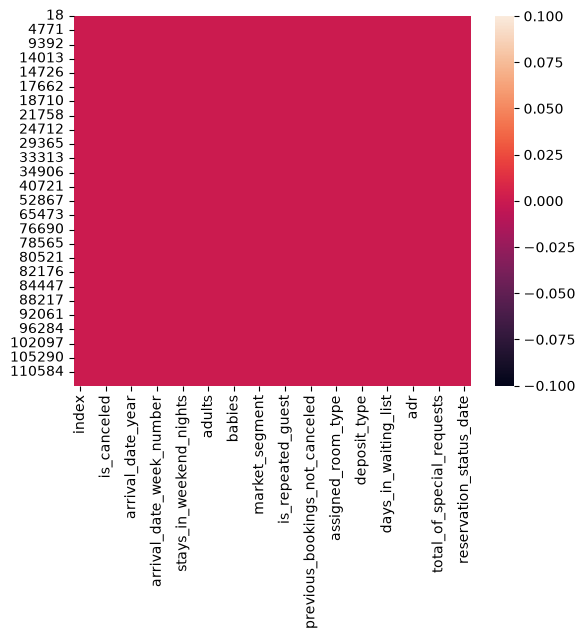

In [75]:
sns.heatmap(df.isnull())
plt.show()

In [70]:
df.shape

(6797, 31)

In [44]:
df.dropna(inplace=True)

In [76]:
df.tail()

,index,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,booking_changes,deposit_type,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119119,119119,City Hotel,0,40,2017,August,35,29,0,1,...,0,No Deposit,451.0,0,Transient,95.0,0,0,Check-Out,30-08-17
119122,119122,City Hotel,0,40,2017,August,35,29,0,1,...,0,No Deposit,451.0,0,Transient,95.0,0,0,Check-Out,30-08-17
119123,119123,City Hotel,0,40,2017,August,35,29,0,1,...,0,No Deposit,451.0,0,Transient,95.0,0,0,Check-Out,30-08-17
119124,119124,City Hotel,0,0,2017,August,35,29,0,1,...,0,No Deposit,72.0,0,Transient,0.0,0,2,Check-Out,30-08-17
119248,119248,City Hotel,0,22,2017,August,35,29,0,3,...,0,No Deposit,485.0,0,Transient,75.0,0,4,Check-Out,01-09-17


In [46]:
df.shape

(6797, 31)

In [47]:
df.size

210707

In [48]:
df.iloc[:,0:16].info()

<class 'pandas.DataFrame'>
Index: 6797 entries, 18 to 119248
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   index                      6797 non-null   int64  
 1   hotel                      6797 non-null   str    
 2   is_canceled                6797 non-null   int64  
 3   lead_time                  6797 non-null   int64  
 4   arrival_date_year          6797 non-null   int64  
 5   arrival_date_month         6797 non-null   str    
 6   arrival_date_week_number   6797 non-null   int64  
 7   arrival_date_day_of_month  6797 non-null   int64  
 8   stays_in_weekend_nights    6797 non-null   int64  
 9   stays_in_week_nights       6797 non-null   int64  
 10  adults                     6797 non-null   int64  
 11  children                   6797 non-null   float64
 12  babies                     6797 non-null   int64  
 13  meal                       6797 non-null   str    
 14  marke

In [49]:
print(df['children'].dtype)
print(df['children'].isnull().sum())
print(df['children'].unique())

float64
0
[0. 1. 2. 3.]


In [71]:
df['children'] = df['children'].fillna(df['children'].median())

In [72]:
df['children'] = df['children'].astype(int)

In [52]:
print(df['children'].dtype)
print(df['children'].isnull().sum())

int64
0


In [53]:
df.describe()

,index,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000,6797.000000
mean,55142.262027,0.175224,49.087980,2016.147859,25.765779,15.695160,0.490511,1.868324,1.302045,0.015448,0.002648,0.245697,0.160071,1.785788,0.435486,189.266735,0.294983,67.274186,0.112403,0.250405
std,35508.208292,0.380187,83.355696,0.714188,15.570111,8.550549,0.802497,1.696999,0.489276,0.157871,0.051397,0.430531,0.607468,5.638983,0.892959,131.655015,5.071176,34.200345,0.317742,0.590514
min,18.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000
25%,20036.000000,0.000000,3.000000,2016.000000,12.000000,9.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,62.000000,0.000000,42.000000,0.000000,0.000000
50%,52152.000000,0.000000,9.000000,2016.000000,23.000000,15.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,179.000000,0.000000,66.000000,0.000000,0.000000
75%,85269.000000,0.000000,51.000000,2017.000000,42.000000,22.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,270.000000,0.000000,87.130000,0.000000,0.000000
max,119248.000000,1.000000,365.000000,2017.000000,53.000000,31.000000,14.000000,35.000000,4.000000,3.000000,1.000000,1.000000,6.000000,72.000000,21.000000,543.000000,185.000000,315.000000,2.000000,4.000000


In [54]:
df.isnull().sum()

index                             0
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

In [55]:
df.shape

(6797, 31)

In [56]:
df.duplicated().sum()

np.int64(0)

In [77]:
df.drop_duplicates().sum()

index                                                                     374801955
hotel                             Resort HotelResort HotelResort HotelResort Hot...
is_canceled                                                                    1191
lead_time                                                                    333651
arrival_date_year                                                          13703757
arrival_date_month                JulyJulyJulyJulyJulyJulyJulyJulyJulyJulyJulyAu...
arrival_date_week_number                                                     175130
arrival_date_day_of_month                                                    106680
stays_in_weekend_nights                                                        3334
stays_in_week_nights                                                          12699
adults                                                                         8850
children                                                                    

In [58]:
df.shape

(6797, 31)

In [59]:
df.nunique()


index                             6797
hotel                                2
is_canceled                          2
lead_time                          198
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             10
stays_in_week_nights                22
adults                               5
children                             4
babies                               2
meal                                 5
market_segment                       7
distribution_channel                 4
is_repeated_guest                    2
previous_cancellations               7
previous_bookings_not_canceled      72
reserved_room_type                   9
assigned_room_type                  11
booking_changes                     11
deposit_type                         3
company                            352
days_in_waiting_list                23
customer_type            

In [60]:
df.columns

Index(['index', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'assigned_room_type', 'booking_changes',
       'deposit_type', 'company', 'days_in_waiting_list', 'customer_type',
       'adr', 'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [61]:
df.dtypes

index                               int64
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                            int64
babies                              int64
meal                                  str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
company                           

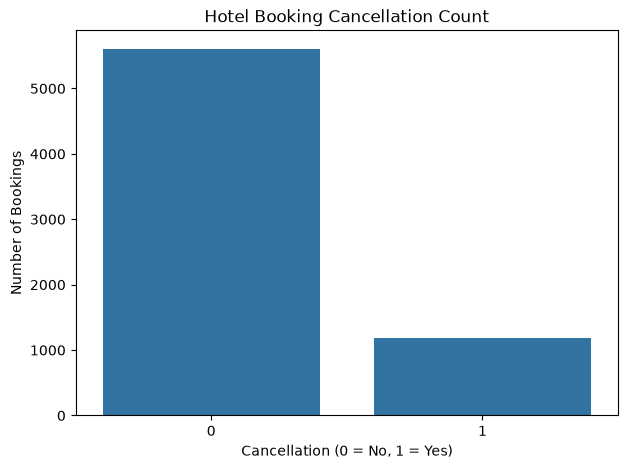

In [62]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='is_canceled')

plt.title('Hotel Booking Cancellation Count')
plt.xlabel('Cancellation (0 = No, 1 = Yes)')
plt.ylabel('Number of Bookings')

plt.show()

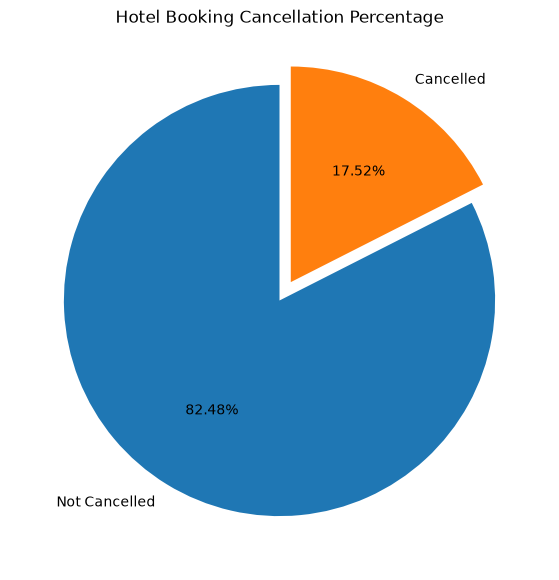

In [63]:
plt.figure(figsize=(7,7))

cancel_count = df['is_canceled'].value_counts()

plt.pie(cancel_count,
        labels=['Not Cancelled', 'Cancelled'],
        autopct='%1.2f%%',
        startangle=90,
        explode=(0, 0.1))

plt.title('Hotel Booking Cancellation Percentage')

plt.show()

In [64]:
df.shape

(6797, 31)

In [65]:
df.columns

Index(['index', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'assigned_room_type', 'booking_changes',
       'deposit_type', 'company', 'days_in_waiting_list', 'customer_type',
       'adr', 'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')